# LiverGuard-DNN: Early Detection of Liver Disorders via Deep Learning on Serum Enzyme Panels

Following Code is entirely done by : SADAF M. ANIS
this code is part of the research -

> ***"LiverGuard-DNN: Early Detection of Liver Disorders via Deep Learning on Serum Enzyme Panel"***


> **Authors :** **Sadaf M. Anis**, Marzia Mahzabin Mahi,Fariha Tahsin, Basim Ahamed Shikto and Professor Md Golam Rabiul Alam



> This research work was presented at 3rd International Conference on Big Data, IoT and Machine Learning (BIM2025) on 26th September, 2025


> The publication is under process for inclusion in the **Taylor and Francis book series**

⚠️ *This code is provided solely by the first author, Sadaf M. Anis, for review purposes. Redistribution, reproduction, or sharing of this code without explicit permission is strictly prohibited.*












Dataset details : Dataset from UCL ML Repository :  
A. HCV Laboratory Data (UCI)
Contains Hepatitis C lab results, including ALT, AST, bilirubin, albumin, and more.
The data set contains laboratory values of blood donors and Hepatitis C patients and demographic values like age.

Labels: various liver disease outcomes (you can simplify to binary: diseased vs healthy).

Format: ~615 rows × 13 numeric features, CSV.
https://archive.ics.uci.edu/dataset/571/hcv+data



In [ ]:
pip install pandas scikit-learn tensorflow matplotlib seaborn shap


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from tensorflow.keras import layers, models, regularizers, utils
import shap
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("hcvdat0.csv")
df.drop(columns=["Unnamed: 0"], inplace=True)

#Keep only key classes remove suspect blood donor
df = df[~df['Category'].str.contains('suspect', case=False)]

#####################
category_map = {
    '0=Blood Donor': 0,
    '1=Hepatitis': 1,
    '2=Fibrosis': 2,
    '3=Cirrhosis': 3
}
df['target'] = df['Category'].map(category_map)
df.drop(columns=["Category"], inplace=True)
df['Sex'] = LabelEncoder().fit_transform(df['Sex'])


df.dropna(inplace=True)
X = df.drop(columns=["target"])
y = df['target']
X_cols = X.columns

#########
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
y_cat = utils.to_categorical(y)
#########
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_cat, stratify=y_cat, test_size=0.2, random_state=42)


In [ ]:
pip install imbalanced-learn


In [ ]:
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras import regularizers, layers, models
import numpy as np
from imblearn.over_sampling import ADASYN
y_train_int = np.argmax(y_train, axis=1)

#ADASYN
adasyn = ADASYN(random_state=42)
X_train_resampled, y_train_resampled = adasyn.fit_resample(X_train, y_train_int)
y_train_resampled_cat = tf.keras.utils.to_categorical(y_train_resampled, num_classes=4)
print("Original training class distribution:", np.bincount(y_train_int))
print("Resampled training class distribution (ADASYN):", np.bincount(y_train_resampled))

Original training class distribution: [420  16  10  19]
Resampled training class distribution (ADASYN): [420 420 423 417]


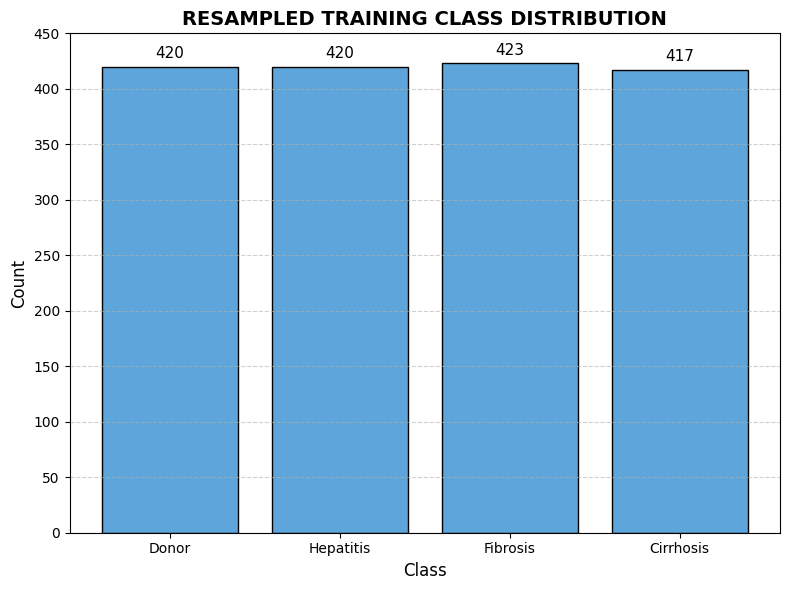

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

#ADASYN-resampled class distribution
classes = ['Donor', 'Hepatitis', 'Fibrosis', 'Cirrhosis']
counts = [420, 420, 423, 417]

# Custom color
bar_color = '#5DA5DA'
plt.figure(figsize=(8, 6))
bars = plt.bar(classes, counts, color=bar_color, edgecolor='black')
plt.title('RESAMPLED TRAINING CLASS DISTRIBUTION', fontsize=14, weight='bold')
plt.xlabel('Class', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.ylim(0, 450)
##############################################
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 5,
             f'{height}', ha='center', va='bottom', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()




In [ ]:
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Input, Dense, Dropout, Multiply, Softmax
import numpy as np
import tensorflow as tf


l1_l2_reg = regularizers.l1_l2(l1=0.001, l2=0.001)

# -------------------- Base DNN Model --------------------
def create_base_dnn(input_dim):
    model = models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(input_dim,), kernel_regularizer=l1_l2_reg),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu', kernel_regularizer=l1_l2_reg),
        layers.Dropout(0.3),
        layers.Dense(4, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# -------------------- Feature-wise Attention Block --------------------
def attention_block(inputs):
    attention_probs = Dense(inputs.shape[1], activation='softmax', name='attention_vec')(inputs)
    attention_mul = Multiply()([inputs, attention_probs])
    return attention_mul

# -------------------- Attention-Enhanced DNN --------------------
def create_attention_dnn(input_dim):
    input_layer = Input(shape=(input_dim,))
    x = Dense(64, activation='relu', kernel_regularizer=l1_l2_reg)(input_layer)
    x = attention_block(x)  # feature-wise attention applied here
    x = Dense(32, activation='relu', kernel_regularizer=l1_l2_reg)(x)
    x = Dropout(0.3)(x)
    output = Dense(4, activation='softmax')(x)

    model = models.Model(inputs=input_layer, outputs=output)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# -------------------- Train Models --------------------
input_dim = X_train.shape[1]
base_dnn = create_base_dnn(input_dim)
attention_dnn = create_attention_dnn(input_dim)

# Train Base DNN
history1 = base_dnn.fit(
    X_train_resampled, y_train_resampled_cat,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

# Train Attention DNN
history2 = attention_dnn.fit(
    X_train_resampled, y_train_resampled_cat,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

# -------------------- Ensemble: Soft Voting --------------------
y_pred_prob_1 = base_dnn.predict(X_test)
y_pred_prob_2 = attention_dnn.predict(X_test)

# Average predictions
y_pred_ensemble = (y_pred_prob_1 + y_pred_prob_2) / 2

# Final prediction
y_pred = np.argmax(y_pred_ensemble, axis=1)
y_true = np.argmax(y_test, axis=1)


Epoch 1/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.3802 - loss: 1.7497 - val_accuracy: 0.5000 - val_loss: 1.8697
Epoch 2/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6530 - loss: 1.3685 - val_accuracy: 0.5595 - val_loss: 1.5496
Epoch 3/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7918 - loss: 1.0975 - val_accuracy: 0.7381 - val_loss: 1.0561
Epoch 4/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8570 - loss: 0.8718 - val_accuracy: 0.7470 - val_loss: 1.0120
Epoch 5/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8766 - loss: 0.7713 - val_accuracy: 0.8601 - val_loss: 0.7227
Epoch 6/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8882 - loss: 0.7046 - val_accuracy: 0.8601 - val_loss: 0.6797
Epoch 7/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8943 - loss: 0.6675 - val_accuracy: 0.8899 - val_loss: 0.5532
Epoch 8/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8975 - loss: 0.6221 - val_accuracy: 0.8958 - val_loss

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


In [ ]:
# Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]))



Classification Report:
              precision    recall  f1-score   support

       Donor       1.00      1.00      1.00       106
   Hepatitis       1.00      0.50      0.67         4
    Fibrosis       0.67      1.00      0.80         2
   Cirrhosis       0.83      1.00      0.91         5

    accuracy                           0.98       117
   macro avg       0.88      0.88      0.84       117
weighted avg       0.99      0.98      0.98       117



In [ ]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    #accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'r*-', label='Validation Accuracy')
    plt.title(f'{model_name} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    #loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation Loss')
    plt.title(f'{model_name} - Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

#Plot for both models



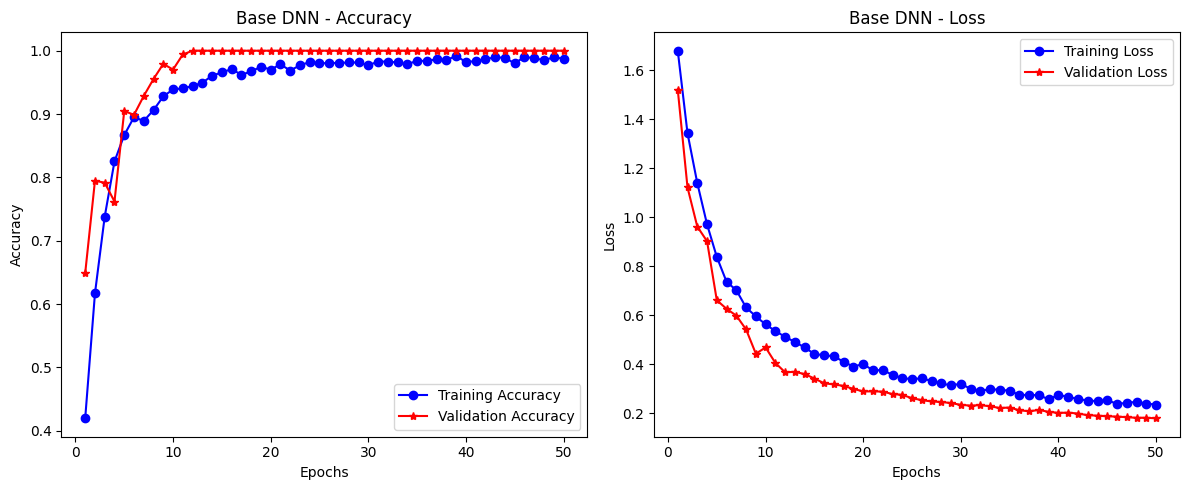

In [ ]:
plot_history(history1, "Base DNN")


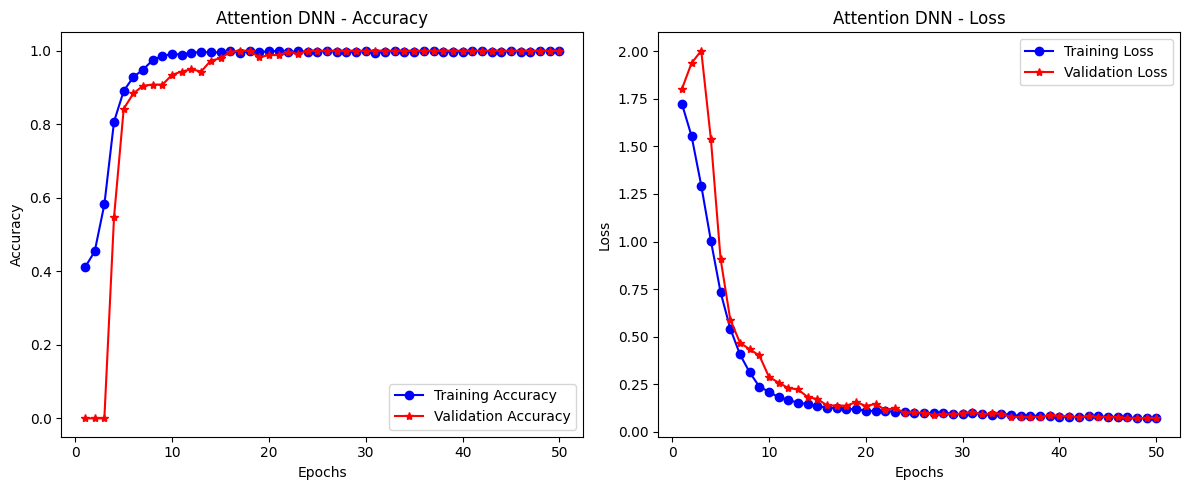

In [ ]:
plot_history(history2, "Attention DNN")

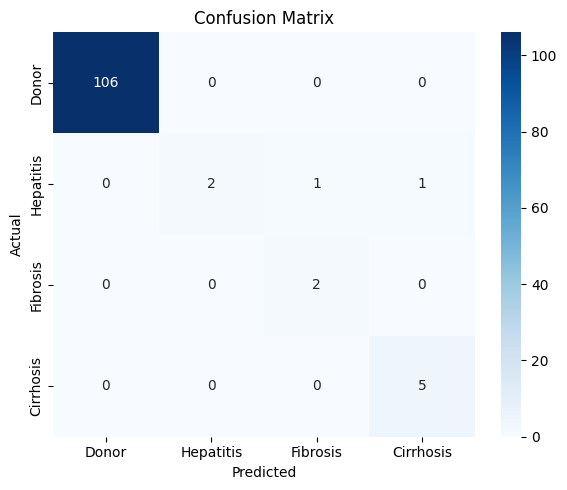

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"],
            yticklabels=["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

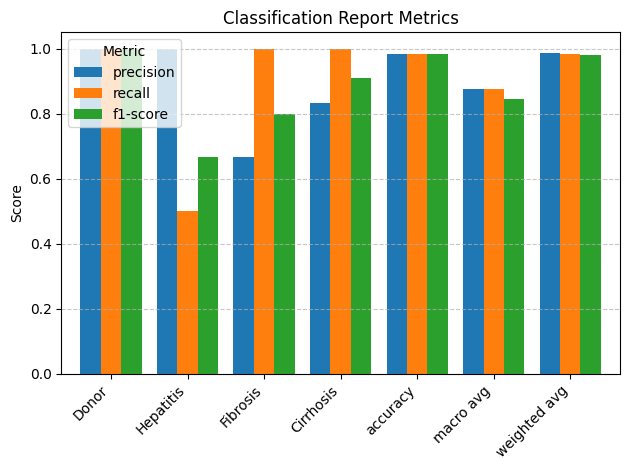

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report


target_names = ["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]
report_dict = classification_report(
    y_true, y_pred,
    target_names=target_names,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).T
metrics = ["precision", "recall", "f1-score"]
plot_df = report_df.loc[target_names + ["accuracy", "macro avg", "weighted avg"], metrics]
plt.figure(figsize=(8, 6))
plot_df.plot(kind="bar", width=0.8)
plt.title("Classification Report Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Metric")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


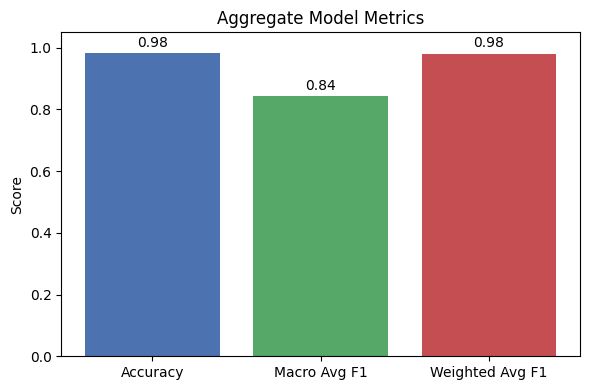

In [ ]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt


report = classification_report(y_true, y_pred, output_dict=True)
scores = {
    'Accuracy':        report['accuracy'],
    'Macro Avg F1':    report['macro avg']['f1-score'],
    'Weighted Avg F1': report['weighted avg']['f1-score']
}

plt.figure(figsize=(6, 4))
bars = plt.bar(scores.keys(), scores.values(), color=['#4C72B0','#55A868','#C44E52'])
plt.ylim(0, 1.05)
for idx, (label, val) in enumerate(scores.items()):
    plt.text(idx, val + 0.02, f'{val:.2f}', ha='center')

plt.title('Aggregate Model Metrics')
plt.ylabel('Score')
plt.tight_layout()
plt.show()

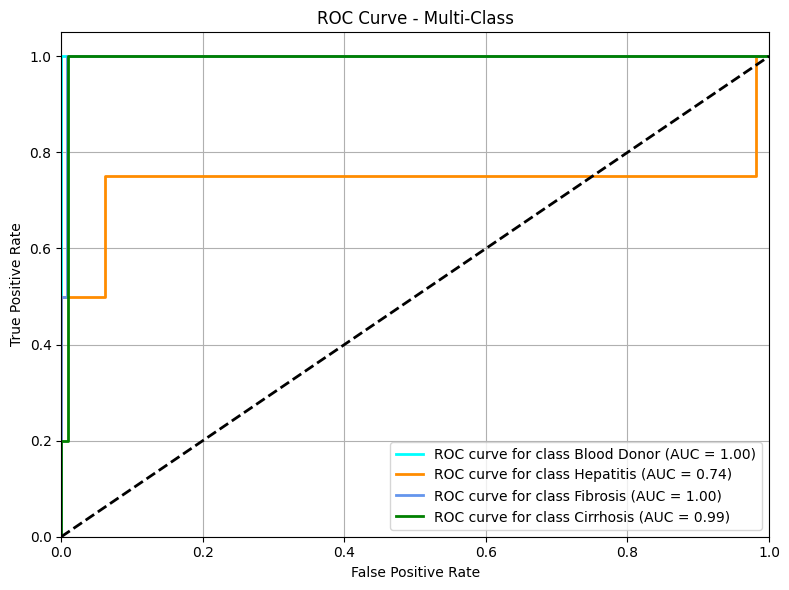

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle

y_test_bin = label_binarize(y_true, classes=[0, 1, 2, 3])  # 4 classes
n_classes = y_test_bin.shape[1]
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_ensemble[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green'])
class_names = ['Blood Donor', 'Hepatitis', 'Fibrosis', 'Cirrhosis']

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve for class {0} (AUC = {1:0.2f})'
                   ''.format(class_names[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)  #Random guess line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Multi-Class')
plt.legend(loc='lower right')
plt.grid()
plt.tight_layout()
plt.show()


In [ ]:
def predict_fn_class(index):
    def predict_fn(X):
        preds = base_dnn.predict(np.array(X))
        return preds[:, index]
    return predict_fn


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

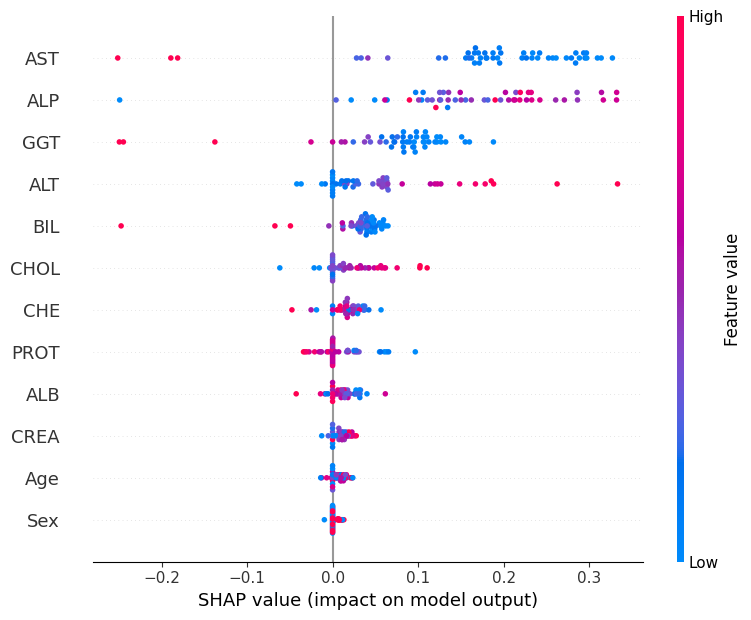

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s

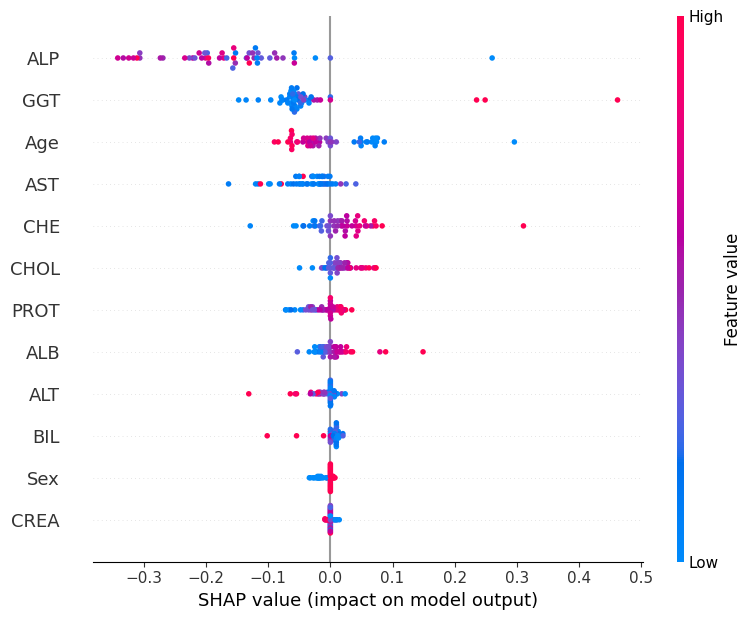

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

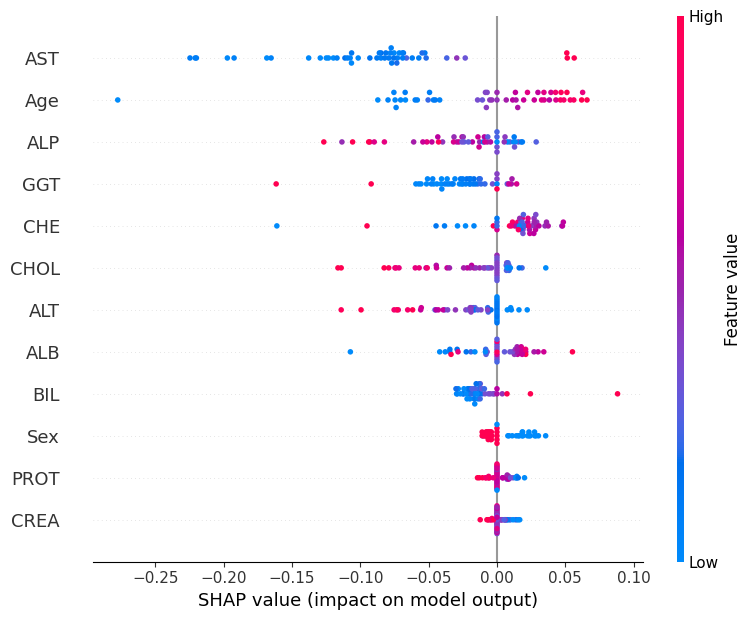

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

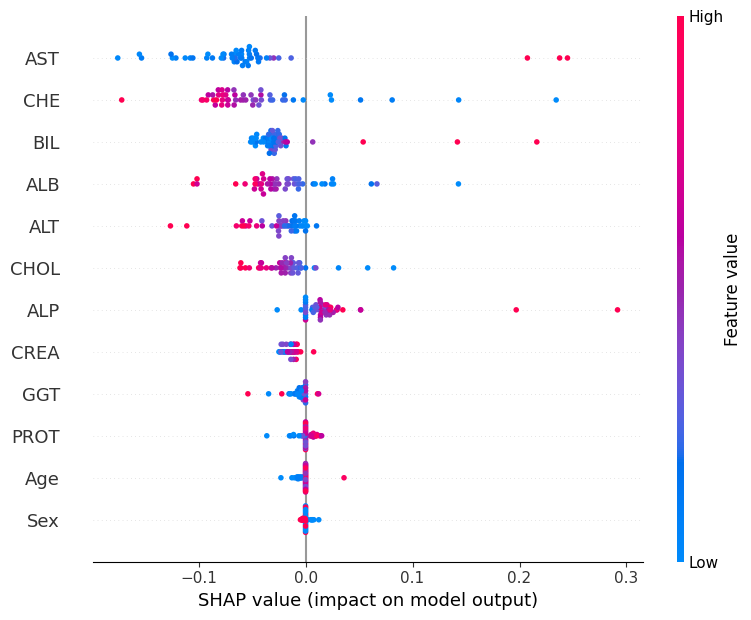

In [ ]:
import shap
class_labels = ["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]

background = X_train_resampled[np.random.choice(X_train_resampled.shape[0], 100, replace=False)]
X_sample = X_test[:50]

for i, cls in enumerate(class_labels):
    explainer = shap.KernelExplainer(predict_fn_class(i), background)
    shap_values = explainer.shap_values(X_sample, nsamples="auto")

    if isinstance(shap_values, np.ndarray) and shap_values.shape[0] == X_sample.shape[0]:
        shap.summary_plot(shap_values, X_sample, feature_names=X_cols, show=True, title=f"SHAP Summary - {cls}")
    else:
        print(f"[Warning] Skipping plot for class {cls} due to shape mismatch.")


In [ ]:
!pip install alibi
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from alibi.explainers import AnchorTabular

df = pd.read_csv("hcvdat0.csv")
df.dropna(inplace=True)

if 'Sex' in df.columns:
    df['Sex'] = LabelEncoder().fit_transform(df['Sex'])
label_encoder = LabelEncoder()
df['Category_encoded'] = label_encoder.fit_transform(df['Category'])
X = df.drop(columns=["Category", "Category_encoded"])
y = df["Category_encoded"]
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
explainer = AnchorTabular(clf.predict, feature_names)
explainer.fit(X_train.values)

############################################################
instance = X_test.iloc[0].values
explanation = explainer.explain(instance)

#anchor rule
print("Anchor Rule:", explanation.anchor)
print("Precision:", explanation.precision)
print("Coverage:", explanation.coverage)


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local

Anchor Rule: ['ALP > 52.50', 'AST <= 31.70']
Precision: 0.9942196531791907
Coverage: 0.557


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=79c78c45d489895ad2bebb154a3ef2559c15836104711cd35618a7ef6682aba5
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [ ]:
import lime
import lime.lime_tabular
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("hcvdat0.csv")
df.drop(columns=["Unnamed: 0"], inplace=True)
df = df[~df['Category'].str.contains('suspect', case=False)]
category_map = {
    '0=Blood Donor': 0,
    '1=Hepatitis': 1,
    '2=Fibrosis': 2,
    '3=Cirrhosis': 3
}
df['target'] = df['Category'].map(category_map)
df.drop(columns=["Category"], inplace=True)
df['Sex'] = LabelEncoder().fit_transform(df['Sex'])
df.dropna(inplace=True)

X_raw = df.drop(columns=["target"]).values
y_raw = df["target"].values
X_cols = df.drop(columns=["target"]).columns
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
######################################################################
X_train_raw, X_test_raw, _, _ = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=42)
X_train_scaled, X_test_scaled = train_test_split(X_scaled, test_size=0.2, stratify=y_raw, random_state=42)
class_names = ["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]

#LIME Tabular Explainer
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_raw,
    feature_names=X_cols.tolist(),
    class_names=class_names,
    mode='classification',
    discretize_continuous=True
)

i = 10
X_instance = X_test_raw[i]
def predict_fn(x):
    x_scaled = scaler.transform(x)
    return model.predict(x_scaled)

exp = explainer.explain_instance(X_instance, predict_fn, num_features=8, top_labels=4)
exp.show_in_notebook(show_table=True, show_all=False)
exp.save_to_file("lime_explanation_instance10.html")

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


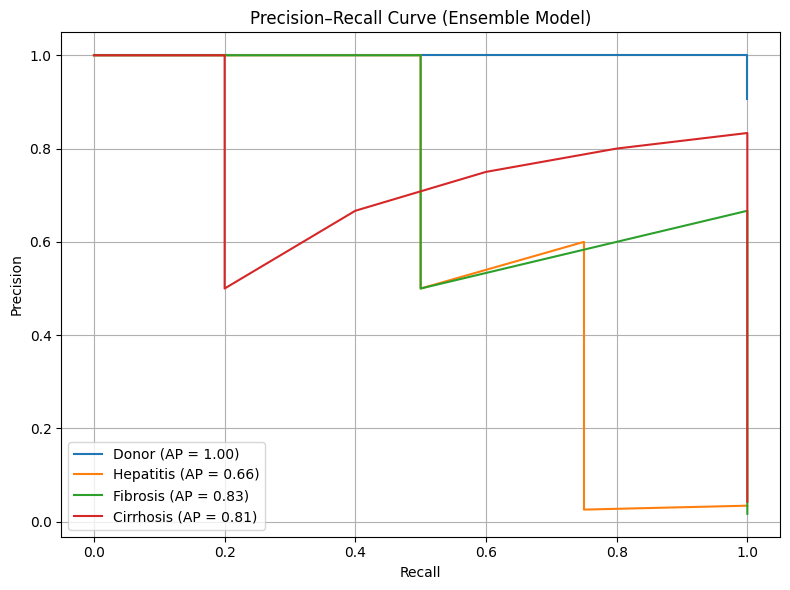

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

class_names = ["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]
n_classes = y_test.shape[1]

plt.figure(figsize=(8, 6))
for i, label in enumerate(class_names):
    precision, recall, _ = precision_recall_curve(y_test[:, i], y_pred_ensemble[:, i])
    ap_score = average_precision_score(y_test[:, i], y_pred_ensemble[:, i])
    plt.plot(recall, precision, label=f"{label} (AP = {ap_score:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve (Ensemble Model)")
plt.legend(loc='lower left')
plt.grid(True)
plt.tight_layout()
plt.show()


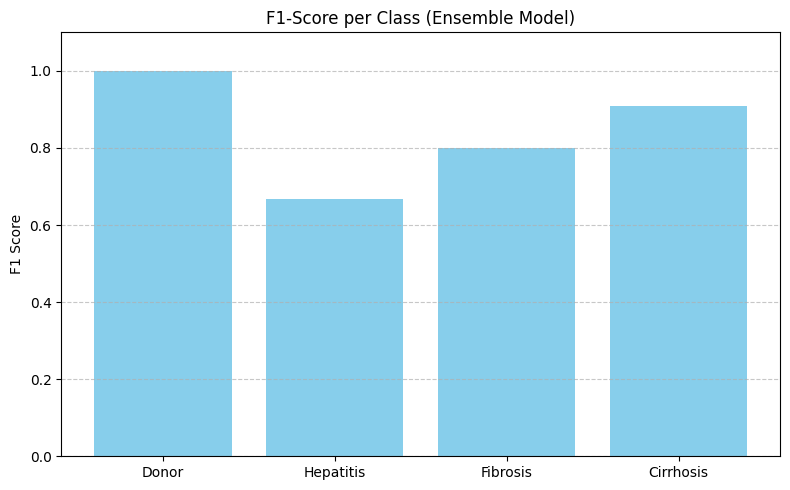

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

class_names = ["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]

y_true = np.argmax(y_test, axis=1)

#Ensemble prediction already computed:
# y_pred_ensemble = (y_pred_prob_1 + y_pred_prob_2) / 2
# Let's assume it's already available, so:
y_pred = np.argmax(y_pred_ensemble, axis=1)

f1s = f1_score(y_true, y_pred, average=None)
plt.figure(figsize=(8, 5))
plt.bar(class_names, f1s, color='skyblue')
plt.title("F1-Score per Class (Ensemble Model)")
plt.ylabel("F1 Score")
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


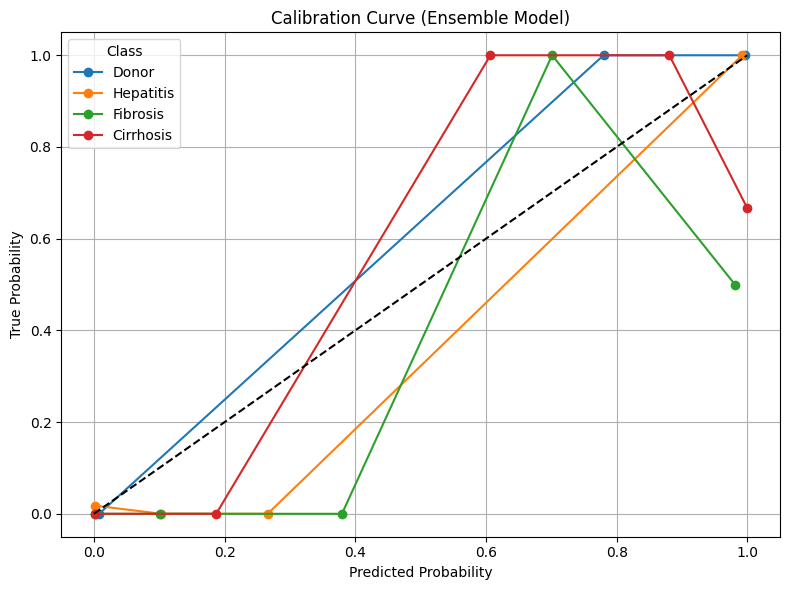

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# y_pred_ensemble = (y_pred_prob_1 + y_pred_prob_2) / 2

plt.figure(figsize=(8, 6))

for i, label in enumerate(class_names):
    prob_true, prob_pred = calibration_curve(
        y_test[:, i],                #True binary labels for class i
        y_pred_ensemble[:, i],      #Predicted probabilities for class i
        n_bins=10,
        strategy='uniform'          #Opt:'quantile' also works
    )
    plt.plot(prob_pred, prob_true, marker='o', label=label)

plt.plot([0, 1], [0, 1], linestyle='--', color='black')  #p.calibration
plt.xlabel("Predicted Probability")
plt.ylabel("True Probability")
plt.title("Calibration Curve (Ensemble Model)")
plt.legend(title="Class")
plt.grid(True)
plt.tight_layout()
plt.show()


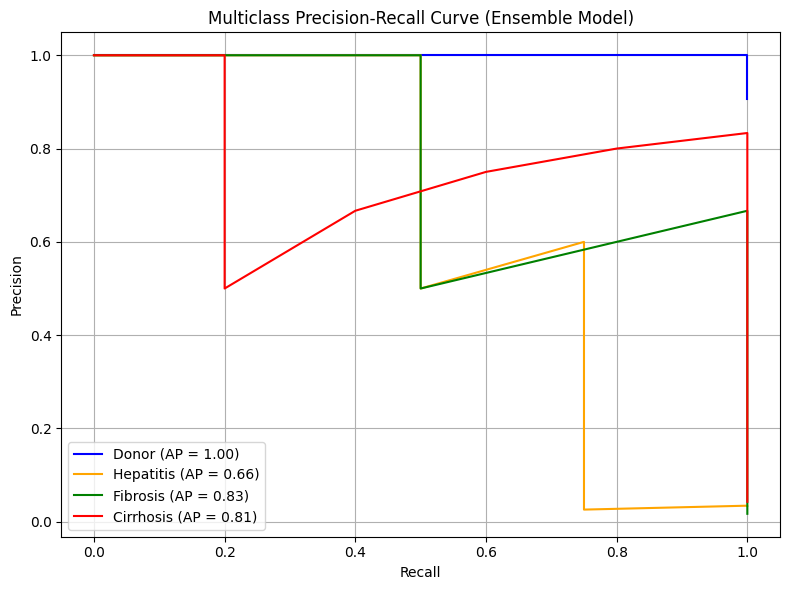

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# y_pred_ensemble = (y_pred_prob_1 + y_pred_prob_2) / 2

n_classes = y_test.shape[1]
precision, recall, average_precision = dict(), dict(), dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_test[:, i], y_pred_ensemble[:, i])
    average_precision[i] = average_precision_score(y_test[:, i], y_pred_ensemble[:, i])


class_names = ["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]
colors = ['blue', 'orange', 'green', 'red']
plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], color=colors[i],
             label=f'{class_names[i]} (AP = {average_precision[i]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Multiclass Precision-Recall Curve (Ensemble Model)')
plt.legend(loc='lower left')
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
#Work after reviewer feedback - cross validation and others


In [ ]:

import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, balanced_accuracy_score,
    average_precision_score
)
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
from imblearn.over_sampling import ADASYN

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

g = globals()
if 'X_scaled' in g and isinstance(g['X_scaled'], np.ndarray):
    _X_scaled = g['X_scaled']
elif 'X' in g:
    _X_vals = g['X'].values if hasattr(g['X'], "values") else np.asarray(g['X'])
    _X_scaled = StandardScaler().fit_transform(_X_vals)
else:
    raise RuntimeError("Could not locate X or X_scaled.")

if 'y_cat' in g:
    _y_cat = g['y_cat']
    _y_int = np.argmax(_y_cat, axis=1)
elif 'y' in g:
    _y_arr = g['y'].values if hasattr(g['y'], "values") else np.asarray(g['y'])
    if _y_arr.ndim == 2 and _y_arr.shape[1] > 1:
        _y_cat = _y_arr
        _y_int = np.argmax(_y_cat, axis=1)
    else:
        _y_arr = _y_arr.astype(int)
        _y_cat = tf.keras.utils.to_categorical(_y_arr)
        _y_int = _y_arr.astype(int)
else:
    raise RuntimeError("Could not locate y or y_cat.")

if 'X_cols' in g:
    _X_cols = list(g['X_cols'])
elif 'X' in g and hasattr(g['X'], "columns"):
    _X_cols = list(g['X'].columns)
else:
    _X_cols = [f"f{i}" for i in range(_X_scaled.shape[1])]

_input_dim = _X_scaled.shape[1]
_n_classes = _y_cat.shape[1] if _y_cat.ndim == 2 else len(np.unique(_y_int))

print(f"[Resolver] input_dim={_input_dim}, n_classes={_n_classes}, n_features={len(_X_cols)}")
print("Class distribution:", dict(zip(*np.unique(_y_int, return_counts=True))))


[Resolver] input_dim=12, n_classes=4, n_features=12
Class distribution: {np.int64(0): np.int64(526), np.int64(1): np.int64(20), np.int64(2): np.int64(12), np.int64(3): np.int64(24)}


In [ ]:
def build_model(
    input_dim,
    n_classes,
    hidden_units=(64, 32),
    use_dropout=True,
    dropout_rate=0.40,
    use_l1l2=True,
    l1_strength=1e-3,
    l2_strength=1e-3
):
    reg = regularizers.l1_l2(l1=l1_strength, l2=l2_strength) if use_l1l2 else None
    m = models.Sequential([layers.Input(shape=(input_dim,))])

    #First hidden
    m.add(layers.Dense(hidden_units[0], activation='relu', kernel_regularizer=reg))
    if use_dropout and dropout_rate > 0:
        m.add(layers.Dropout(dropout_rate))

    #Optional second hidden
    if hidden_units[1] and hidden_units[1] > 0:
        m.add(layers.Dense(hidden_units[1], activation='relu', kernel_regularizer=reg))
        if use_dropout and dropout_rate > 0:
            m.add(layers.Dropout(dropout_rate))

    m.add(layers.Dense(n_classes, activation='softmax'))
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m


In [ ]:
def minority_class(y):
    vals, cnts = np.unique(y, return_counts=True)
    return vals[np.argmin(cnts)]

def run_kfold_cv(
    X, y_int, k=5, epochs=50, batch_size=32,
    use_adasyn=True, use_dropout=True, use_l1l2=True,
    hidden_units=(64,32), dropout_rate=0.40,
    l1_strength=1e-3, l2_strength=1e-3,
    random_state=SEED, verbose=0
):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=random_state)
    fold_rows, conf_accum = [], np.zeros((_n_classes, _n_classes), dtype=int)
    m_class = minority_class(y_int)

    es = callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    rlrop = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=0)

    for fold, (tr, va) in enumerate(skf.split(X, y_int), start=1):

        X_tr_raw, X_va_raw = X[tr], X[va]
        y_tr, y_va = y_int[tr], y_int[va]

        # --- Scale on TRAIN only (no leakage) ---
        scaler = StandardScaler().fit(X_tr_raw)
        X_tr, X_va = scaler.transform(X_tr_raw), scaler.transform(X_va_raw)

        # --- ADASYN strictly on TRAIN only ---
        if use_adasyn:
            ad = ADASYN(random_state=random_state, n_neighbors=5)
            X_tr, y_tr = ad.fit_resample(X_tr, y_tr)

        y_tr_cat = tf.keras.utils.to_categorical(y_tr, num_classes=_n_classes)
        y_va_cat = tf.keras.utils.to_categorical(y_va, num_classes=_n_classes)

        model = build_model(
            input_dim=X_tr.shape[1], n_classes=_n_classes,
            hidden_units=hidden_units, use_dropout=use_dropout,
            dropout_rate=dropout_rate, use_l1l2=use_l1l2,
            l1_strength=l1_strength, l2_strength=l2_strength
        )
        model.fit(
            X_tr, y_tr_cat, epochs=epochs, batch_size=batch_size,
            validation_data=(X_va, y_va_cat), verbose=verbose,
            callbacks=[es, rlrop]
        )

        y_prob = model.predict(X_va, verbose=0)
        y_hat = np.argmax(y_prob, axis=1)

        row = {
            "fold": fold,
            "accuracy": accuracy_score(y_va, y_hat),
            "balanced_accuracy": balanced_accuracy_score(y_va, y_hat),
            "f1_macro": f1_score(y_va, y_hat, average='macro'),
            "precision_macro": precision_score(y_va, y_hat, average='macro', zero_division=0),
            "recall_macro": recall_score(y_va, y_hat, average='macro', zero_division=0),
            "recall_minority": recall_score(y_va == m_class, y_hat == m_class, zero_division=0)
        }
        try:
            y_va_bin = tf.keras.utils.to_categorical(y_va, num_classes=_n_classes)
            row["auc_macro"] = roc_auc_score(y_va_bin, y_prob, average='macro', multi_class='ovr')
            row["ap_minority"] = average_precision_score((y_va == m_class).astype(int), y_prob[:, m_class])
        except Exception:
            row["auc_macro"] = np.nan
            row["ap_minority"] = np.nan

        fold_rows.append(row)
        conf_accum += confusion_matrix(y_va, y_hat, labels=list(range(_n_classes)))

    df = pd.DataFrame(fold_rows)
    summary = df.mean(numeric_only=True).to_dict()

    for m in ["accuracy","balanced_accuracy","f1_macro","recall_macro","recall_minority"]:
        summary[f"std_{m}"] = df[m].std()

    summary.update({
        "k": k, "use_adasyn": use_adasyn, "use_dropout": use_dropout, "use_l1l2": use_l1l2,
        "hidden_units": str(hidden_units), "dropout_rate": dropout_rate,
        "l1": l1_strength, "l2": l2_strength
    })
    return df, summary, conf_accum


In [ ]:
#Ablation configurations
_configs = [
    {"name": "Baseline",
     "use_adasyn": True,  "use_dropout": True,  "use_l1l2": True,
     "hidden_units": (64, 32), "dropout_rate": 0.40, "l1": 1e-3, "l2": 1e-3},

    {"name": "No ADASYN",
     "use_adasyn": False, "use_dropout": True,  "use_l1l2": True,
     "hidden_units": (64, 32), "dropout_rate": 0.40, "l1": 1e-3, "l2": 1e-3},

    {"name": "No Dropout",
     "use_adasyn": True,  "use_dropout": False, "use_l1l2": True,
     "hidden_units": (64, 32), "dropout_rate": 0.00, "l1": 1e-3, "l2": 1e-3},

    {"name": "No L1/L2",
     "use_adasyn": True,  "use_dropout": True,  "use_l1l2": False,
     "hidden_units": (64, 32), "dropout_rate": 0.40, "l1": 0.0,  "l2": 0.0},

    {"name": "No Reg (No Dropout & No L1/L2)",
     "use_adasyn": True,  "use_dropout": False, "use_l1l2": False,
     "hidden_units": (64, 32), "dropout_rate": 0.00, "l1": 0.0,  "l2": 0.0},

    {"name": "Shallow (64)",
     "use_adasyn": True,  "use_dropout": True,  "use_l1l2": True,
     "hidden_units": (64, 0),  "dropout_rate": 0.40, "l1": 1e-3, "l2": 1e-3},

    {"name": "Tiny (32)",
     "use_adasyn": True,  "use_dropout": True,  "use_l1l2": True,
     "hidden_units": (32, 0),  "dropout_rate": 0.40, "l1": 1e-3, "l2": 1e-3},
]

# cross vali for all configs
_results, _confmats = [], {}
for cfg in _configs:
    df_folds, summary, cm = run_kfold_cv(
        X=_X_scaled, y_int=_y_int, k=5, epochs=50, batch_size=32, verbose=0,
        use_adasyn=cfg["use_adasyn"],
        use_dropout=cfg["use_dropout"],
        use_l1l2=cfg["use_l1l2"],
        hidden_units=cfg["hidden_units"],
        dropout_rate=cfg["dropout_rate"],
        l1_strength=cfg["l1"], l2_strength=cfg["l2"],
        random_state=SEED
    )
    summary["config"] = cfg["name"]
    _results.append(summary)
    _confmats[cfg["name"]] = cm

results_df = pd.DataFrame(_results)
results_df


,fold,accuracy,balanced_accuracy,f1_macro,precision_macro,recall_macro,recall_minority,auc_macro,ap_minority,std_accuracy,...,std_recall_minority,k,use_adasyn,use_dropout,use_l1l2,hidden_units,dropout_rate,l1,l2,config
0,3.0,0.962216,0.696905,0.686548,0.689299,0.696905,0.333333,0.957497,0.529708,0.011485,...,0.408248,5,True,True,True,"(64, 32)",0.4,0.001,0.001,Baseline
1,3.0,0.960492,0.644524,0.628560,0.642015,0.644524,0.100000,0.979343,0.608333,0.011485,...,0.223607,5,False,True,True,"(64, 32)",0.4,0.001,0.001,No ADASYN
2,3.0,0.955335,0.682619,0.668836,0.677509,0.682619,0.400000,0.919013,0.340933,0.007132,...,0.252763,5,True,False,True,"(64, 32)",0.0,0.001,0.001,No Dropout
3,3.0,0.957059,0.710000,0.668255,0.645677,0.710000,0.333333,0.946601,0.485890,0.010470,...,0.471405,5,True,True,False,"(64, 32)",0.4,0.000,0.000,No L1/L2
4,3.0,0.955349,0.672262,0.666728,0.678461,0.672262,0.366667,0.929146,0.430635,0.017564,...,0.414997,5,True,False,False,"(64, 32)",0.0,0.000,0.000,No Reg (No Dropout & No L1/L2)
5,3.0,0.960492,0.701905,0.697842,0.708470,0.701905,0.433333,0.947614,0.507250,0.013027,...,0.365148,5,True,True,True,"(64, 0)",0.4,0.001,0.001,Shallow (64)
6,3.0,0.960477,0.713929,0.701972,0.713338,0.713929,0.433333,0.943379,0.530058,0.014431,...,0.365148,5,True,True,True,"(32, 0)",0.4,0.001,0.001,Tiny (32)


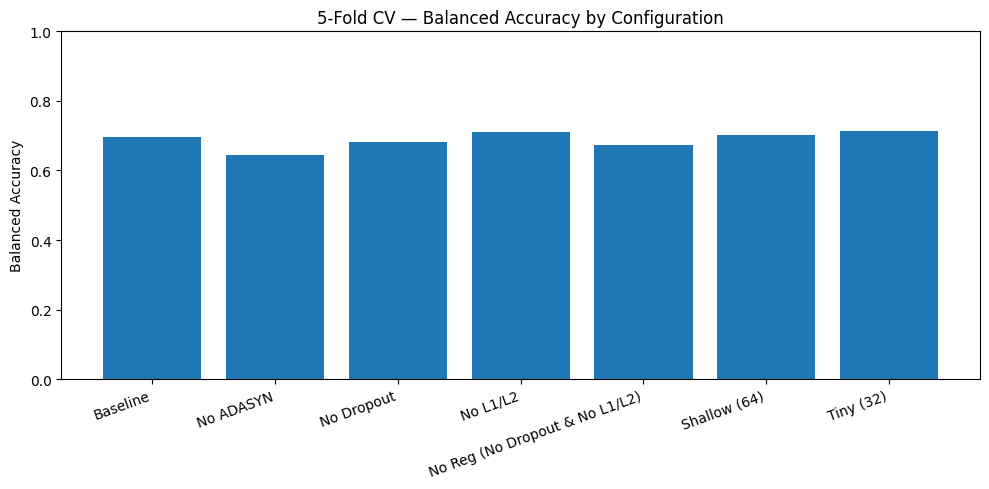

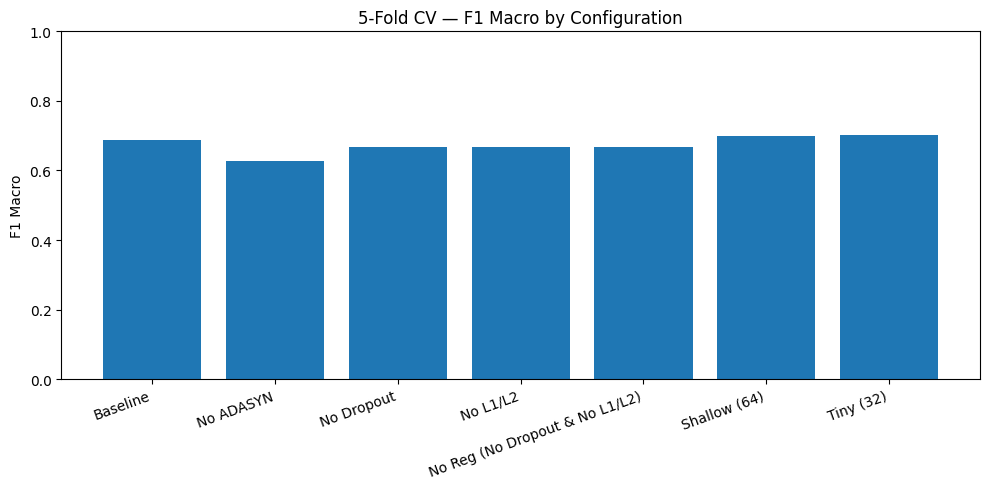

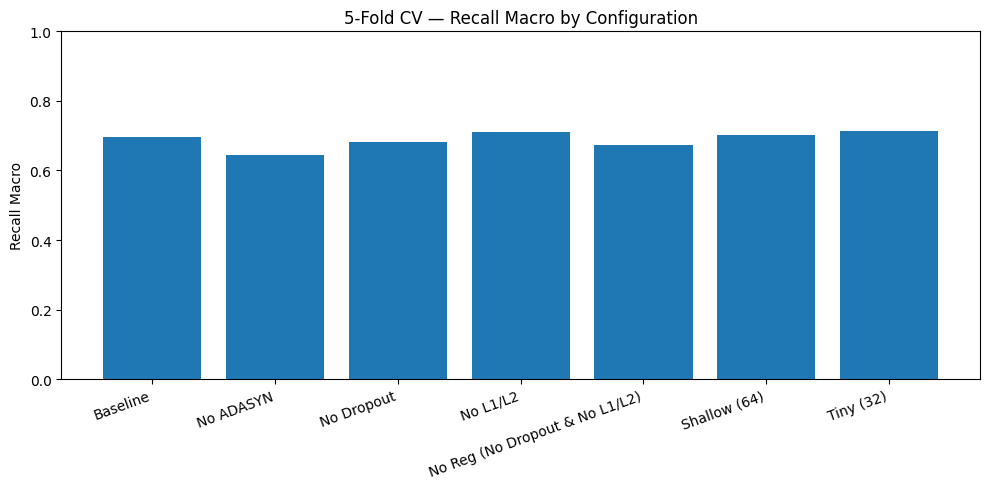

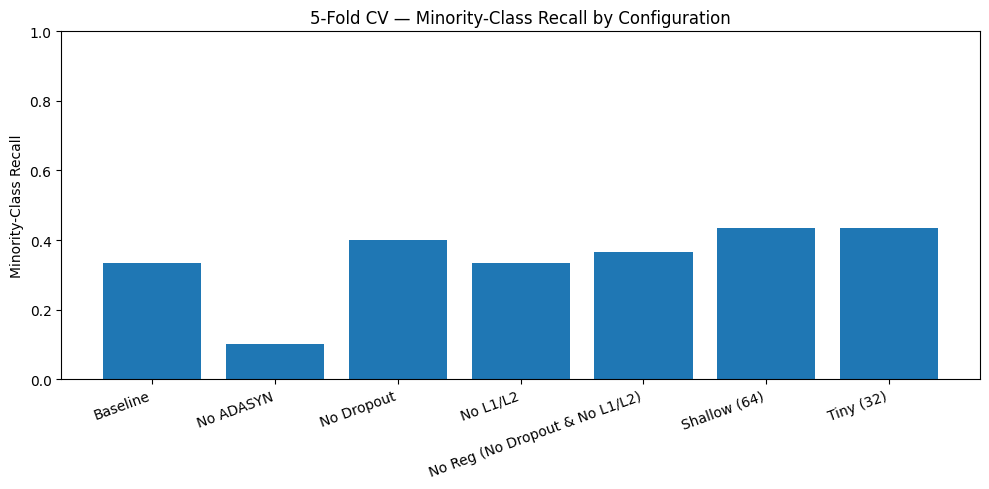

In [ ]:
def bar_no_err(metric, ylabel, title):
    plt.figure(figsize=(10,5))
    x = np.arange(len(results_df))
    plt.bar(x, results_df[metric])
    plt.xticks(x, results_df["config"], rotation=20, ha='right')
    plt.ylim(0, 1.0); plt.ylabel(ylabel); plt.title(title)
    plt.tight_layout(); plt.show()

bar_no_err("balanced_accuracy", "Balanced Accuracy",
           "5-Fold CV — Balanced Accuracy by Configuration")
bar_no_err("f1_macro", "F1 Macro",
           "5-Fold CV — F1 Macro by Configuration")
bar_no_err("recall_macro", "Recall Macro",
           "5-Fold CV — Recall Macro by Configuration")
bar_no_err("recall_minority", "Minority-Class Recall",
           "5-Fold CV — Minority-Class Recall by Configuration")


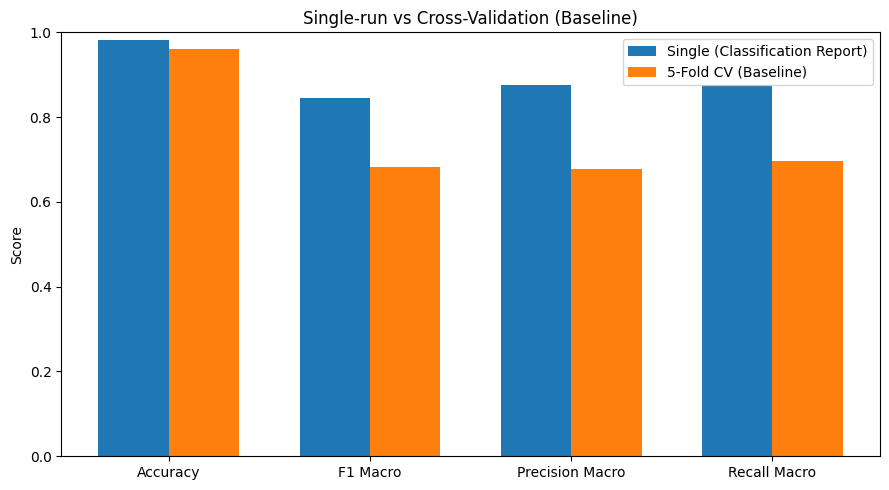

In [ ]:
_single = {}
if 'y_true' in g and 'y_pred' in g:
    yt, yp = g['y_true'], g['y_pred']
    _single["accuracy"] = accuracy_score(yt, yp)
    _single["f1_macro"] = f1_score(yt, yp, average='macro')
    _single["precision_macro"] = precision_score(yt, yp, average='macro', zero_division=0)
    _single["recall_macro"] = recall_score(yt, yp, average='macro', zero_division=0)
else:
    _single = {"accuracy": 0.98, "f1_macro": 0.98, "precision_macro": 0.98, "recall_macro": 0.98}

df_base, base_summary, _ = run_kfold_cv(
    X=_X_scaled, y_int=_y_int, k=5, epochs=50, batch_size=32, verbose=0,
    use_adasyn=True, use_dropout=True, use_l1l2=True,
    hidden_units=(64,32), dropout_rate=0.40, l1_strength=1e-3, l2_strength=1e-3,
    random_state=SEED
)

labels = ["Accuracy","F1 Macro","Precision Macro","Recall Macro"]
cv_means = [
    df_base["accuracy"].mean(),
    df_base["f1_macro"].mean(),
    df_base["precision_macro"].mean(),
    df_base["recall_macro"].mean()
]
cv_stds = [
    df_base["accuracy"].std(),
    df_base["f1_macro"].std(),
    df_base["precision_macro"].std(),
    df_base["recall_macro"].std()
]
single_vals = [
    _single["accuracy"], _single["f1_macro"],
    _single["precision_macro"], _single["recall_macro"]
]

x = np.arange(len(labels)); width = 0.35
plt.figure(figsize=(9,5))
plt.bar(x - width/2, single_vals, width, label="Single (Classification Report)")
plt.bar(x + width/2, cv_means, width, label="5-Fold CV (Baseline)")  # <- no yerr
plt.ylim(0,1.0); plt.ylabel("Score"); plt.xticks(x, labels); plt.legend()
plt.title("Single-run vs Cross-Validation (Baseline)")
plt.tight_layout(); plt.show()
